In [1]:
import numpy as  np
import matplotlib.pyplot as plt 
from scripts.ansatz import DomainWallAnsatz, Ansatz
from scripts.compiled import Problem, AnswerShooting
import sympy as sm
from scipy.ndimage import shift
import scipy.optimize as opt
import sympy.matrices as mtx
from scipy.interpolate import Akima1DInterpolator
import os 
from tqdm import tqdm

from tqdm import tqdm
from scipy.integrate import solve_ivp
from scripts.mm.experiment import Experiment
from scripts.read_field import read_dir
import scripts.scientific
from scripts.scientific import colors
from scripts.mm.fit import fit

In [42]:
path = os.path.join("./02-attraction/skyrmion_system")
frame = [3,5]
runs = sorted([os.path.join(path, d) for d in os.listdir(path) if d.startswith("drive-")])[frame[0]:frame[1] + 1]
data = np.concat([read_dir(run) for run in runs])
experiments = [Experiment.load(run) for run in runs]

In [ ]:
ps = []
X, Y = None, None
for m in tqdm(data):
    p0 = ps[-1] if len(ps) else None 
    p, X, Y = fit(m, experiment=experiments[0], return_grid=True, p0=p0, method="Nelder-Mead")
    ps.append(p)

ps = np.array(ps)

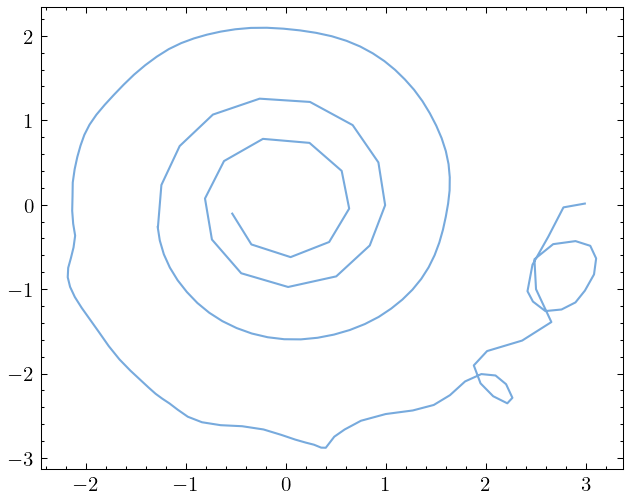

In [4]:
plt.plot(ps[:,0], ps[:,1])

Text(0.5, 1.0, '$\\delta$')

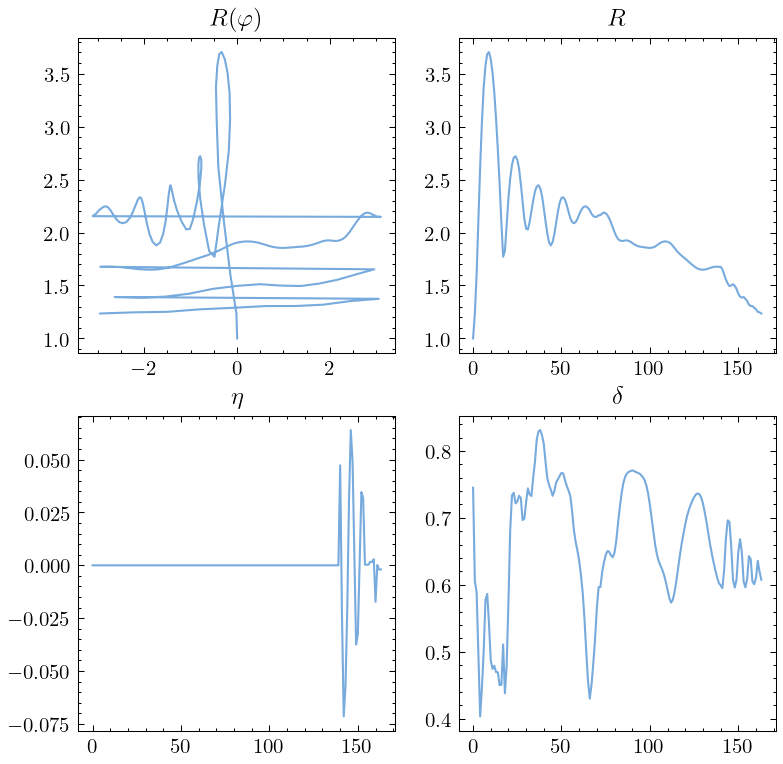

In [61]:
fig, axs = plt.subplots(2,2, figsize=(6,6))
axs[0,0].plot(np.atan2(ps[:,1],ps[:,0]), ps[:,2])
axs[0,0].set_title("$R(\\varphi)$")
axs[1,0].plot(ps[:,4])
axs[1,0].set_title("$\\eta$")
axs[0,1].plot(ps[:,2])
axs[0,1].set_title("$R$")
axs[1,1].plot(ps[:,3])
axs[1,1].set_title("$\\delta$")

In [44]:
from typing import Literal
from tqdm import tqdm
from scipy.interpolate import make_smoothing_spline

def trajectory(data, experiment: Experiment, method: Literal['center', 'charge'] = 'center', lam=1e-11):
    xs = np.array([])
    ys = np.array([])
    W = experiment.width / experiment.dx
    H = experiment.height / experiment.dx
    X, Y = np.meshgrid(np.arange(-W, W) * experiment.dx, -np.arange(-H, H) * experiment.dx)
    for i in range(len(data)):
        if method == 'center':
            weight = (1- data[i,:,:,2]) ** 2
        if method == 'charge':
            weight = np.sum(data[i] * np.linalg.cross(np.gradient(data[i], axis=0), np.gradient(data[i], axis=1)), axis=2)
        norm = np.sum(weight)

        x = np.sum(weight * X) / norm
        y = np.sum(weight * Y) / norm
        xs = np.append(xs, x)
        ys = np.append(ys, y)

    xs = xs - experiment.vortex_to[0]
    ys = ys - experiment.vortex_to[1]
    t = np.linspace(0, 1, len(xs))
    t_fine = np.linspace(0, 1, len(xs) * 3)
    xs, ys =  make_smoothing_spline(t,xs, lam=lam)(t_fine), make_smoothing_spline(t,ys, lam=lam)(t_fine)

    return xs, ys

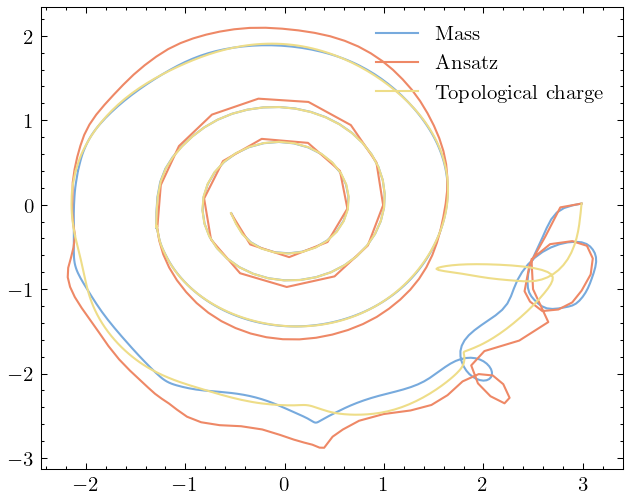

In [50]:
xs, ys = trajectory(data, experiments[0], method='center', lam=1e-20)
xs_2, ys_2 = trajectory(data, experiments[0], method='charge', lam=1e-20)

plt.plot(xs, ys, label='Mass')

plt.plot(ps[:,0], ps[:,1], label="Ansatz")
plt.plot(xs_2, ys_2, label="Topological charge")
plt.legend()

In [110]:
problem = Problem(epsilon=0.5, beta=-3, chi=1, distance=0)
center = [0, 0]
start = [3, 0]
problem.beta = 2
problem.distance = 3
fix_eta = False 
sol_positive = solve_for(
    problem.beta, start,
    count=10000,
    R=1,
    w=0.75,
    eta=0,
    time=250,
    alpha=0.05
).y
sol_fixed = solve_for(
    problem.beta, start,
    count=10000,
    R=1,
    w=0.75,
    eta=0,
    time=250,
    alpha=0.05,
    fix_eta=True
).y

In [112]:
from scripts.scatter import Search

res, = Search.ranged(beta=2, count=10, epsilon=0.5, chi=[1], problem=problem, distances=np.linspace(0,3, 100))

100%|██████████| 100/100 [00:03<00:00, 26.61it/s]


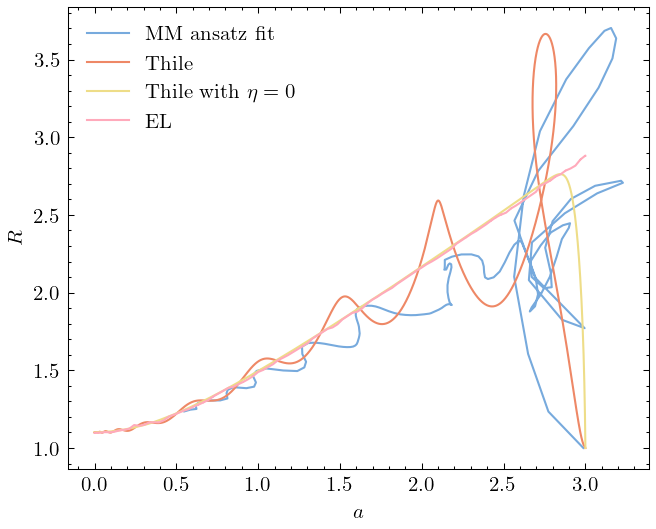

In [122]:
plt.plot(np.sqrt(ps[:,0] ** 2 + ps[:,1] ** 2), ps[:,2], label="MM ansatz fit")
plt.plot(np.sqrt(sol_positive[0] ** 2 + sol_positive[1] ** 2), sol_positive[2], label="Thile")
plt.plot(np.sqrt(sol_fixed[0] ** 2 + sol_fixed[1] ** 2), sol_fixed[2], label="Thile with $\\eta = 0$")
plt.plot(res.distances, res.radii, label="EL")
plt.ylabel("$R$")
plt.xlabel("$a$")
plt.legend()

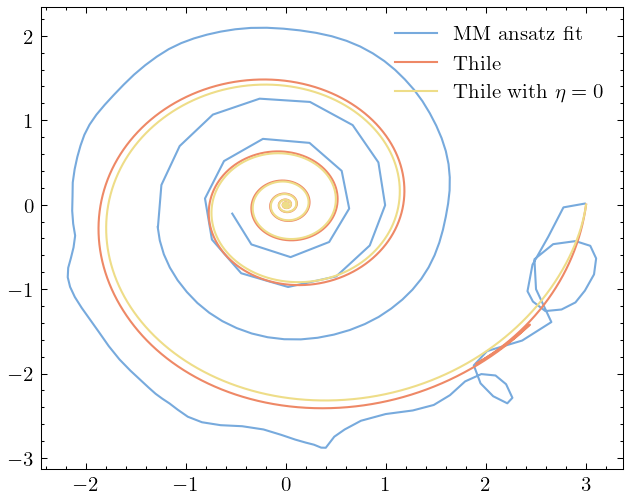

In [121]:
plt.plot(ps[:,0] , ps[:,1], label="MM ansatz fit")
plt.plot(sol_positive[0] , sol_positive[1], label="Thile")
plt.plot(sol_fixed[0] , sol_fixed[1], label="Thile with $\\eta = 0$")
plt.legend()

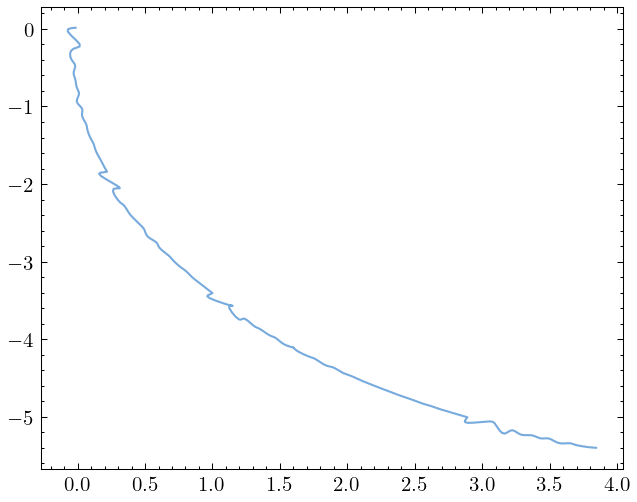

In [60]:
path = os.path.join("./01-repulsion/skyrmion_system")
runs = sorted([os.path.join(path, d) for d in os.listdir(path) if d.startswith("drive-")])[5:]
data_negative = [read_dir(run) for run in runs]
experiments_negative = [Experiment.load(run) for run in runs]

ts = [trajectory(d, e, method='center', lam=1e-6) for d, e in zip(data_negative, experiments_negative)]
xs, ys = [], []
curr = [np.float64(0), np.float64(0)]
for t in ts:
    xs = [*xs, *t[0]]
    ys = [*ys, *t[1]]

plt.plot(xs,ys)

In [ ]:
plt.plot()

In [107]:
from scripts.compiled import field_a, field

problem = Problem(epsilon=0.5, beta=-3, chi=1, distance=0)
dr = 1e-5
dumping = 0.01
# default ansatz
ansatz = Ansatz(
    theta = lambda r, x, _: DomainWallAnsatz.theta(r, x[0], x[1]),
    theta_r = lambda r, x, _: DomainWallAnsatz.theta_r(r, x[0], x[1]),
)

center = [0,0]

def quad(r, dens):
    return np.diff(r) @ (np.copy(dens[:-1]) + dens[1:])

def q0(R, w):
    return 1 / np.tanh(R / w) / w

def q1(R,w):
    density = 0.5 * problem.r * np.sin(ansatz.theta(problem.r, [R,w], problem)) ** 2
    return quad(problem.r, density)

def q2(R,w):
    density = 0.25 * problem.r * (
        ansatz.theta_r(problem.r, [R,w], problem) ** 2 + np.sin(ansatz.theta(problem.r, [R,w], problem)) ** 2 / problem.r ** 2
    )
    return quad(problem.r, density)

def q3(R,w):
    density = 2 * problem.r * np.sin(ansatz.theta(problem.r, [R,w], problem) / 2) ** 2

    return -q0(R,w) * q1(R,w) * R / w + quad(problem.r, density) / w

def q4(R, w):
    density = 0.5 * problem.r ** 3 * (
        ansatz.theta_r(problem.r, [R,w], problem) ** 2 + np.sin(ansatz.theta(problem.r, [R,w], problem)) ** 2 / problem.r ** 2
    )

    return -q1(R,w) * ((R * q0(R,w)) ** 2 + 1) / w ** 2 - 2 * q0(R,w) * q3(R,w) * R / w + quad(problem.r, density) / w**2

eta_fixed = False 

def step(t, y):
    a = y[0]
    phi = y[1]
    R = y[2]
    w = y[3]
    if eta_fixed == False:
        h = y[4]
    else:
        h = 0
    
    # getting distances 
    problem.distance = a

    # real energy density 
    theta = ansatz.theta(problem.r, [R, w], problem)
    theta_r = ansatz.theta_r(problem.r, [R, w], problem)
    exchange_density = ( 2 * problem.r * theta_r + np.sin(2 * theta));
    
    _beta = problem.beta
    _epsilon = problem.epsilon
    problem.beta = _beta * np.cos(h)
    problem.epsilon = _epsilon * np.cos(h)

    dR = 1e-5
    energy_R = (problem.answer_energy(AnswerShooting(problem.r, ansatz.theta(problem.r, [R + dR, w], problem), ansatz.theta_r(problem.r, [R + dR, w], problem)))-problem.answer_energy(AnswerShooting(problem.r, theta, theta_r))) / dR
    energy_w = (problem.answer_energy(AnswerShooting(problem.r, ansatz.theta(problem.r, [R, w + dR], problem), ansatz.theta_r(problem.r, [R, w + dR], problem)))-problem.answer_energy(AnswerShooting(problem.r, theta, theta_r))) / dR
    energy_h = - np.sin(h) * problem.field_energy(
        problem.r, 
        ansatz.theta(problem.r, [R, w], problem),
        ansatz.theta_r(problem.r, [R, w], problem)
    ) 

    L = problem.distance

    density = np.vectorize(field_a)(problem.r, problem.height, L) * exchange_density
    energy_L = problem.beta * (np.pi * np.diff(problem.r) @ (np.copy(density[:-1]) + density[1:]))

    Q0 = q0(R,w)
    Q1 = q1(R,w)
    Q2 = q2(R,w)
    Q3 = q3(R,w)
    Q4 = q4(R,w)

    if eta_fixed == True:
        D = np.array([
            [Q2, 0,         0,            0,      ],
            [0,  Q2 * a**2, 0,            0,      ],
            [0,  0,         Q0 ** 2 * Q1, Q0 * Q3,],
            [0,  0,         Q0 * Q3     , Q4,     ],
        ]);
        G = np.array([
            [0,  a, 0, 0],
            [-a, 0, 0, 0],
            [0,  0, 0, 0],
            [0,  0, 0, 0],
        ]);
    
        M = dumping * D - G
        b = -np.array([energy_L, 0, energy_R, energy_w]) / (8 * np.pi)
        problem.beta = _beta
        problem.epsilon = _epsilon

        y_new = np.linalg.inv(M).T @ b
        return y_new

    D = np.array([
        [Q2, 0,         0,            0,       0 ],
        [0,  Q2 * a**2, 0,            0,       0 ],
        [0,  0,         Q0 ** 2 * Q1, Q0 * Q3, 0 ],
        [0,  0,         Q0 * Q3     , Q4,      0 ],
        [0,  0,         0,            0,       Q1],
    ]);
    G = np.array([
        [0,  a, 0,        0,   0      ],
        [-a, 0, 0,        0,   0      ],
        [0,  0, 0,        0,   Q0 * Q1],
        [0,  0, 0,        0,   Q3     ],
        [0,  0, -Q0 * Q1, -Q3, 0      ]
    ]);

    M = dumping * D - G
    b = -np.array([energy_L, 0, energy_R, energy_w, energy_h]) / (8 * np.pi)

    problem.beta = _beta
    problem.epsilon = _epsilon

    y_new = np.linalg.inv(M).T @ b
    
    return y_new

In [71]:
def likely_rw():
    solutions = problem.probe_shooting(problem.r)
    rs = np.array([problem.answer_R(ans) for ans in solutions])
    ws = np.array([
        opt.curve_fit(lambda x, R, w: DomainWallAnsatz.theta(x, R, w), ans.r, ans.theta, p0=[1,1])[0][1] for ans in solutions
        ])
    idx = np.argmin(rs[rs > 0.1])
    return rs[rs > 0.1][idx], np.abs(ws[rs > 0.1][idx])

In [109]:
def solve_for(
        beta = 0,
        pos = [-5,0],
        R = None,
        w = None, 
        eta = 0,
        count = 1000,
        time = 50,
        alpha=0.5,
        fix_eta = False
):
    global dumping
    global center
    global problem
    problem.beta=beta
    problem.distance=np.sqrt((pos[0] - center[0]) **2 + (pos[1] - center[1]) ** 2)
    angle = np.atan2(pos[1] - center[1], pos[0] - center[0])
    dumping = alpha
    if (R is None) or (w is None):
        R, w = likely_rw()

    if fix_eta:
        y0 = [problem.distance, angle, R, w]
    else:
        y0 = [problem.distance, angle, R, w, eta]


    global eta_fixed
    eta_fixed = fix_eta
    sol = solve_ivp(
        step,
        t_span=[0,time],
        y0=y0,
        t_eval=np.linspace(0,time,count+1),
        method='LSODA'
    )
    sol.y[:2] = np.vstack([sol.y[0] * np.cos(sol.y[1]) + center[0], sol.y[0] * np.sin(sol.y[1]) + center[1]])
    return sol 

In [18]:
# problem.distance = 3
# problem.beta = 2
# problem.epsilon = 0.5
# center = [0,0]

# sol_positive = solve_for(
#     problem.beta, [3,0],
#     count=10000,
#     R=1,
#     w=0.75,
#     eta=0,
#     time=500,
#     alpha=0.05
# )
# plt.plot(sol_positive.y[0][:1000], sol_positive.y[1][:1000])
# plt.plot(sol_positive_d.y[0][:1000], sol_positive_d.y[1][:1000])

In [19]:
# phi_d = np.arctan2(sol_positive_d.y[1], sol_positive_d.y[0])
# phi = np.arctan2(sol_positive.y[1], sol_positive.y[0])

# plt.plot(phi[:1000], sol_positive.y[2][:1000])
# plt.plot(phi_d[:1000], sol_positive_d.y[2][:1000])

In [11]:
rx, ry = (np.array([0, -2.79424299e-02, -3.17879590e-02, -2.49395930e-02, -2.95389889e-02,
        -3.38831168e-02, -3.00089618e-02, -2.48013504e-02, -1.68543330e-02,
        -7.47100920e-03,  1.21066149e-03,  9.23019576e-03,  2.34044422e-02,
         3.88069732e-02,  5.66155635e-02,  7.46455573e-02,  9.46349253e-02,
         1.16881278e-01,  1.40361289e-01,  1.64957242e-01,  1.85943473e-01,
         1.97459815e-01,  2.01713735e-01,  2.19590703e-01,  2.56803496e-01,
         2.82333172e-01,  3.09432343e-01,  3.41399363e-01,  3.76333887e-01,
         4.13866008e-01,  4.54489665e-01,  4.93097502e-01,  5.31393831e-01,
         5.73673378e-01,  6.16224356e-01,  6.61426256e-01,  7.06231038e-01,
         7.53472719e-01,  8.01922436e-01,  8.51091201e-01,  9.00073620e-01,
         9.43591435e-01,  9.74228122e-01,  9.95014148e-01,  1.03120091e+00,
         1.08906319e+00,  1.13913485e+00,  1.18891763e+00,  1.24203568e+00,
         1.29907728e+00,  1.35694371e+00,  1.41595980e+00,  1.47346464e+00,
         1.52851581e+00,  1.57580199e+00,  1.61192062e+00,  1.65378869e+00,
         1.70948415e+00,  1.77030988e+00,  1.83377922e+00,  1.89729618e+00,
         1.96025845e+00,  2.02402960e+00,  2.08813503e+00,  2.15298351e+00,
         2.21847537e+00,  2.28419904e+00,  2.34991125e+00,  2.41621263e+00,
         2.48275659e+00,  2.55026041e+00,  2.61893858e+00,  2.68832862e+00,
         2.75644108e+00,  2.81669974e+00,  2.86084578e+00,  2.89141322e+00,
         2.93699060e+00,  3.01135751e+00,  3.08818261e+00,  3.15715577e+00,
         3.22280462e+00,  3.29072453e+00,  3.36154783e+00,  3.43117791e+00,
         3.49940111e+00,  3.56856238e+00,  3.63800003e+00,  3.70691179e+00,
         3.77793265e+00,  3.84724489e+00]),
 np.array([0, 0.02650327, -0.06861172, -0.17472685, -0.2756699 , -0.37514524,
        -0.47003893, -0.56204607, -0.65358571, -0.74755879, -0.84214192,
        -0.93620005, -1.02851636, -1.12083133, -1.21356972, -1.30392239,
        -1.3950225 , -1.48582206, -1.57699926, -1.6664099 , -1.74762567,
        -1.81282912, -1.86407859, -1.92678645, -2.01090965, -2.09875112,
        -2.19399714, -2.27957865, -2.35899723, -2.43563576, -2.51530173,
        -2.5948635 , -2.67390018, -2.75064419, -2.8269662 , -2.90344891,
        -2.97705668, -3.05132096, -3.1237405 , -3.19653676, -3.26749516,
        -3.33292408, -3.38794127, -3.433978  , -3.48601733, -3.54867533,
        -3.61668517, -3.69215802, -3.75524294, -3.81620171, -3.87604732,
        -3.93668667, -3.99426602, -4.04815053, -4.09044152, -4.12408571,
        -4.16530368, -4.21548227, -4.26765497, -4.32144029, -4.37182764,
        -4.42206568, -4.47098838, -4.5187738 , -4.5652579 , -4.61062106,
        -4.65472776, -4.69781289, -4.7399448 , -4.78089907, -4.82122398,
        -4.86009682, -4.89812266, -4.93487894, -4.97000828, -5.00266801,
        -5.03170955, -5.05705283, -5.08120548, -5.11962122, -5.16545439,
        -5.19453794, -5.21981357, -5.24351968, -5.26847116, -5.29368135,
        -5.3212302 , -5.3438568 , -5.36460183, -5.38393422, -5.40022392]))
rx_pos, ry_pos = (np.array([3,  2.91340522,  2.74624481,  2.60612852,  2.51710497,  2.49654002,
         2.54644294,  2.65176941,  2.78544443,  2.91751266,  3.02541396,
         3.09275572,  3.10549326,  3.05191904,  2.93043067,  2.75547324,
         2.55605947,  2.35943586,  2.1779237 ,  2.01766655,  1.89745154,
         1.83966289,  1.84918745,  1.90693687,  1.9786989 ,  2.02796674,
         2.02866599,  1.97220851,  1.86505158,  1.71990579,  1.54726756,
         1.35258394,  1.14147485,  0.92748741,  0.73113141,  0.57014188,
         0.45177896,  0.37203838,  0.31867584,  0.27522923,  0.2253533 ,
         0.15623525,  0.06001755, -0.06584469, -0.21802458, -0.38708579,
        -0.5591803 , -0.7201528 , -0.86026371, -0.97655672, -1.07179955,
        -1.15197139, -1.22462118, -1.29768631, -1.37751029, -1.46684711,
        -1.56432583, -1.66536321, -1.76384005, -1.85410456, -1.93249039,
        -1.99739464, -2.04829963, -2.08515793, -2.10872827, -2.12116824,
        -2.12587765, -2.12628488, -2.12441177, -2.1204889 , -2.11386864,
        -2.1041518 , -2.09128411, -2.07405244, -2.04878185, -2.012858  ,
        -1.9648247 , -1.90389515, -1.83000367, -1.74388157, -1.64697571,
        -1.5413291 , -1.42945418, -1.31404421, -1.19742754, -1.08092934,
        -0.96447689, -0.84668907, -0.72541985, -0.59852435, -0.46458984,
        -0.32343829, -0.17628369, -0.02553317,  0.12567676,  0.27408608,
         0.41692955,  0.55240795,  0.67986305,  0.79962064,  0.91259121,
         1.01976267,  1.12172514,  1.21836272,  1.3087887 ,  1.39150706,
         1.46472032,  1.526678  ,  1.57595042,  1.61155102,  1.63292047,
         1.63985385,  1.63244094,  1.6110289 ,  1.5761708 ,  1.52853   ,
         1.4687588 ,  1.3973995 ,  1.31483431,  1.22128378,  1.11686379,
         1.001721  ,  0.87623362,  0.74121026,  0.59799979,  0.44845858,
         0.29478057,  0.13924916, -0.0160036 , -0.16915102, -0.3186919 ,
        -0.46333636, -0.6018003 , -0.73258356, -0.85383222, -0.96340121,
        -1.05921717, -1.13997521, -1.20607991, -1.26048859, -1.30860933]),
 np.array([0, 0.06253813, -0.18632032, -0.4481039 , -0.70944095, -0.93818144,
        -1.10494419, -1.19461871, -1.20295782, -1.13656033, -1.00971618,
        -0.84738196, -0.68400717, -0.55880226, -0.5064513 , -0.54888405,
        -0.68597906, -0.89258469, -1.12927023, -1.36269599, -1.57667601,
        -1.76292732, -1.90966106, -2.00195664, -2.03159344, -2.00547538,
        -1.94801361, -1.89378017, -1.87392988, -1.9035993 , -1.97724319,
        -2.07522479, -2.17825694, -2.27647376, -2.36665669, -2.44563607,
        -2.5086648 , -2.55123038, -2.57026949, -2.56527512, -2.53909712,
        -2.49650893, -2.44241296, -2.38237508, -2.32365207, -2.27356653,
        -2.23597131, -2.20950582, -2.18921751, -2.16940081, -2.14493464,
        -2.11078344, -2.06169147, -1.99322396, -1.90316937, -1.79223421,
        -1.66405156, -1.5246755 , -1.38145424, -1.24158324, -1.11083957,
        -0.99245476, -0.88614967, -0.78798172, -0.69140461, -0.58919848,
        -0.47557589, -0.34785491, -0.20732022, -0.05921851,  0.0880293 ,
         0.22470369,  0.34373691,  0.44792175,  0.55198275,  0.66063001,
         0.77146191,  0.88153193,  0.98941155,  1.09484937,  1.19780015,
         1.29778941,  1.39378487,  1.48434627,  1.56785319,  1.64276815,
         1.70793593,  1.7628164 ,  1.80746288,  1.84219336,  1.86717127,
         1.88218671,  1.88674434,  1.88034556,  1.86275539,  1.8340977 ,
         1.79476255,  1.74522549,  1.68587983,  1.61692771,  1.53836274,
         1.45007719,  1.35206809,  1.24464166,  1.12850264,  1.00468515,
         0.87438366,  0.73878704,  0.59897444,  0.45587263,  0.31027095,
         0.16290843,  0.0146221 , -0.13350872, -0.28010788, -0.42358098,
        -0.56229241, -0.69474743, -0.81968921, -0.93607904, -1.04299646,
        -1.13952205, -1.22465004, -1.29726022, -1.35617171, -1.40027359,
        -1.42867809, -1.44082539, -1.43649991, -1.41576086, -1.37882251,
        -1.32594756, -1.25741724, -1.1735936 , -1.07503385, -0.96261433,
        -0.83764971, -0.70199229, -0.55806477, -0.40874411, -0.2569586 ]))

In [12]:
problem.beta= -3
problem.distance = 5
problem.epsilon = 0.5

# def fit(p):
#     r = np.sqrt((X - xs_negative[0])**2 + (Y - ys_negative[0]) ** 2)
#     theta = DomainWallAnsatz.theta(r, *p)
#     return np.mean((data_negative[0,:,:,2] - np.cos(theta)) ** 2)

# R, d = opt.minimize(fit, [radius, d]).x

R, d = likely_rw()
print(R,d)

center = [0,0]
sol_negative = solve_for(
    # -3, [xs_negative[0], ys_negative[0]],
    -3, [rx[0] - 5, ry[0]],
    count=10000,
    R=R,
    w=d,
    time=250,
    alpha=0.05
)

0.9992202181421 0.7451931141256128


In [13]:
center = sol_negative.y[:2, -1] + np.array([3, 0]) 
start = sol_negative.y[:,-1]
problem.beta = 2
problem.distance = 3
sol_positive = solve_for(
    problem.beta, start,
    count=10000,
    R=1,
    w=0.75,
    eta=start[4],
    time=250,
    alpha=0.05
)

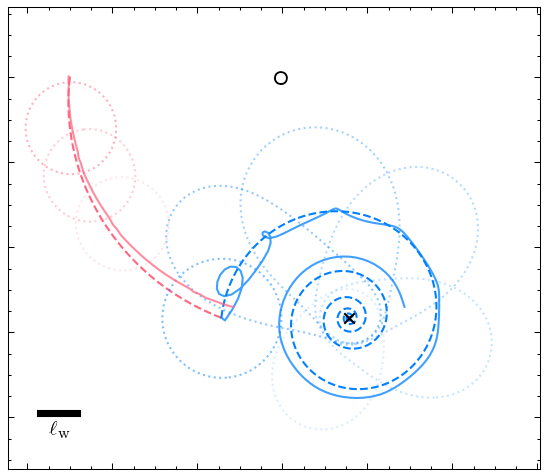

In [16]:
fig, ax = plt.subplots()
# plt.xlim([-7,7])
# plt.ylim([-7,7])
ax.set_aspect(1)

def s(state, alpha=0.1, center=[0,0], color=(0,0,0)):
    color = (*color[:3],alpha)
    c = plt.Circle([state[0], state[1]], state[2], color=color, fill=False)
    # c_p = plt.Circle([state[0], state[1]], state[2] + state[3] / 8, color=color, linestyle='--', fill=False)
    # c_n = plt.Circle([state[0], state[1]], state[2] - state[3] / 8, color=color, linestyle='--', fill=False)
    # a = plt.Arrow(state[0],state[1], (center[0] - state[0]) / 4, (center[1] - state[1]) / 4, width=0.25, color=color)
    ax.add_patch(c)
    # ax.add_patch(c_p)
    # ax.add_patch(c_n)
    # ax.add_patch(a)

color_negative=n_color = (1,0.4,0.5)
color_positive= (0,0.5,1)
plt.plot(sol_negative.y[0][0:], sol_negative.y[1][0:], linestyle="--", color=color_negative, alpha=1)
# plt.scatter(sol_negative.y[0,0::300], sol_negative.y[1][0::300], color=color_negative, s=3)

plt.plot(sol_positive.y[0], sol_positive.y[1], linestyle="--", color=color_positive, alpha=1)
# plt.scatter(sol_positive.y[0,::300], sol_positive.y[1,::300], color=color_positive, s=3)

# for i in range(1,5):
#     s(sol_negative.y[:,i * 1000], alpha=(1 - i /5) / 3, color=color_negative)

# for i in range(0,7):
#     s(sol_positive.y[:,i * 200], alpha=(1 - i /7) / 3, center=center, color=color_positive)

angle = np.pi 
start = 0
xs_p, ys_p = rx_pos[start:] * np.cos(angle) - ry_pos[start:] * np.sin(angle) + center[0], ry_pos[start:] * np.cos(angle) + rx_pos[start:] * np.sin(angle) + center[1]

ylim = plt.ylim()
xlim = plt.xlim()

X_r, Y_r = X * np.cos(angle) - Y * np.sin(angle) + center[0], Y * np.cos(angle) + X * np.sin(angle) + center[1]

for i in range(6):
    alpha = (1 - i / 7) / 2
    plt.contour(
        X_r, Y_r, data[start + i * 65,:,:,2], levels=[0], linestyles=':', colors=(*color_positive, alpha)
    )
    # plt.contour(
    #     X_r, Y_r, data[start + i * 65,:,:,2], levels=[-0.2,0.2], linestyles='--', colors=(*color_positive, alpha)
    # )
ax.plot(xs_p, ys_p, color=color_positive, alpha=0.75)


angle = 0
scale = 1
# angle = 0.39
# scale = 1.06
xs_negative_p, ys_negative_p = xs_negative * np.cos(angle) * scale  - ys_negative * np.sin(angle) * scale, ys_negative * np.cos(angle) * scale + xs_negative * np.sin(angle) * scale
X_r, Y_r = X * np.cos(angle) * scale - Y * np.sin(angle) * scale, Y * np.cos(angle) * scale + X * np.sin(angle) * scale
ax.plot((np.array(rx)- 5), np.array(ry), color=color_negative, alpha=0.75)

for i in range(3):
    alpha = (1 - i / 3) / 2
    plt.contour(
        X_r, Y_r, data_negative[3 + i * 45,:,:,2], linestyles=':', levels=[0], colors=(*color_negative, alpha)
    )
    # plt.contour(
    #     X_r, Y_r, data_negative[3 + i * 45,:,:,2], levels=[-0.2,0.2], linestyles='--', colors=(*color_negative, alpha)
    # )

plt.xlim([xlim[0] - 1, xlim[1] + 2])
plt.ylim([ylim[0] - 1.5, ylim[1] + 1.3])

ax.text(0, 0, r'$\boldsymbol\circ$', color='k', ha='center', va='center', fontsize=15)
plt.scatter(center[0], center[1], color='k', s =25, marker='x', zorder=10)
# ax.set_xlabel("X, in $\\ell_\\text{W}$")
# ax.set_ylabel("Y, in $\\ell_\\text{W}$")
plt.gca().set_xticklabels([])
plt.gca().set_yticklabels([])

from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import matplotlib.font_manager as fm
fontprops = fm.FontProperties(size=10)

scalebar = AnchoredSizeBar(ax.transData,
                           1, '$\\ell_{\\mathrm{w}}$', 'lower left', 
                           pad=1.35,
                           color='black',
                           frameon=False,
                           size_vertical=0.1,
                           fontproperties=fontprops)

ax.add_artist(scalebar)
plt.savefig('article/thiele.pdf')
